# Optional: empirical transition intervals in the superficial-velocity plane

Exploration for Phase 4 of `CLAUDE_PAPER_REVISION_BRIEF.md`. **Not used by the paper.** The objective criterion does not use the superficial velocities; this notebook only describes where the *visual* reference classes change in the $(j_g, j_l)$ plane of the 157 runs.

1. **Observed transition intervals.** The runs lie partly on lines of nearly constant $j_l$ (or $j_g$). Along each line, two neighbouring runs with different visual classes bracket a transition; the interval between them is reported, not an exact boundary.
2. **Descriptive model (optional).** A regularized multinomial logistic regression in $(\log j_g, \log j_l)$, shown only inside the convex hull of the data, with its cross-validated accuracy.

Outputs: `data/gold_layer/optional_flow_map/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import Delaunay
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from src.flow_pattern_criteria import OBJECTIVE_PATTERNS
from src.flow_pattern_report import pattern_styles

CRITERIA_VERSION = 'objective_criteria_10'
LINE_TOL = 1.08        # runs within 8 % of each other share a line of constant velocity
WELL_BRACKETED = 2.0   # interval accepted as well bracketed if j_high / j_low <= 2

gold = project_root / 'data/gold_layer'
out = gold / 'optional_flow_map'
out.mkdir(exist_ok=True)

df = pd.read_csv(gold / CRITERIA_VERSION / 'processed_v2/objective_flow_pattern.csv', index_col=0)
df = df[['run_id', 'jl', 'jg', 'reduced_pattern', 'objective_pattern']].rename(columns={'reduced_pattern': 'visual'})
styles = pattern_styles(list(df['visual'].unique()))
len(df)

157

## Observed transition intervals

Lines of constant $j_l$ (varying $j_g$) and of constant $j_g$ (varying $j_l$): consecutive runs on a line with different visual classes bracket a transition.

In [2]:
def lines(values):
    """Group indices whose values are within LINE_TOL of the previous one (sorted, log scale)."""
    order = np.argsort(values)
    groups, current = [], [order[0]]
    for a, b in zip(order[:-1], order[1:]):
        if values[b] / values[a] <= LINE_TOL:
            current.append(b)
        else:
            groups.append(current)
            current = [b]
    groups.append(current)
    return [g for g in groups if len(g) >= 3]


rows = []

for fixed, varying in (('jl', 'jg'), ('jg', 'jl')):
    for g in lines(df[fixed].to_numpy()):
        sub = df.iloc[g].sort_values(varying)
        for (_, a), (_, b) in zip(sub.iloc[:-1].iterrows(), sub.iloc[1:].iterrows()):
            if a['visual'] != b['visual'] and b[varying] / a[varying] > 1.0001:
                rows.append({
                    'along': varying, 'fixed_value': round(float(sub[fixed].median()), 3),
                    'from': a['visual'], 'to': b['visual'],
                    'low': a[varying], 'high': b[varying], 'ratio': b[varying] / a[varying],
                    'run_low': a['run_id'], 'run_high': b['run_id'],
                    'jl_low': a['jl'], 'jg_low': a['jg'], 'jl_high': b['jl'], 'jg_high': b['jg'],
                })

transitions = pd.DataFrame(rows)
transitions['well_bracketed'] = transitions['ratio'] <= WELL_BRACKETED
transitions['pair'] = transitions.apply(lambda r: ' / '.join(sorted([r['from'], r['to']])), axis=1)
transitions.to_csv(out / 'transition_intervals.csv', index=False)

summary = transitions.groupby(['pair', 'along']).agg(
    brackets=('ratio', 'size'),
    well_bracketed=('well_bracketed', 'sum'),
    fixed_min=('fixed_value', 'min'), fixed_max=('fixed_value', 'max'),
    interval_low_min=('low', 'min'), interval_high_max=('high', 'max'),
    median_ratio=('ratio', 'median'),
).reset_index().sort_values(['brackets'], ascending=False)
summary.to_csv(out / 'transition_summary.csv', index=False)
summary.round(3)

,pair,along,brackets,well_bracketed,fixed_min,fixed_max,interval_low_min,interval_high_max,median_ratio
15,plug / slug,jg,9,3,0.120,0.97,0.39,2.79,2.667
0,annular / wavy,jg,7,6,0.050,0.49,4.13,20.95,1.429
8,churn / dispersed,jl,6,6,3.395,7.87,0.92,1.99,1.421
17,slug / wavy,jg,6,5,0.120,0.49,2.68,10.87,1.478
1,annular / wavy,jl,5,5,12.830,15.76,0.05,0.80,1.400
16,plug / slug,jl,4,2,0.790,2.09,0.12,1.49,2.033
14,dispersed / slug,jl,4,4,1.180,2.71,0.86,1.99,1.382
18,slug / wavy,jl,3,3,2.710,5.43,0.10,0.48,1.333
4,bubbly / plug,jl,3,3,0.260,0.52,0.60,0.97,1.574
7,churn / dispersed,jg,3,3,1.480,1.48,5.36,8.19,1.187


In [3]:
# Reversals: the same pair of classes alternating along one line (ambiguous zones)
alt = transitions.groupby(['along', 'fixed_value', 'pair']).size()
ambiguous = alt[alt >= 2].reset_index(name='changes')
ambiguous.to_csv(out / 'ambiguous_zones.csv', index=False)
ambiguous

,along,fixed_value,pair,changes
0,jg,0.49,annular / wavy,2
1,jg,0.97,bubbly / plug,2
2,jg,1.48,churn / dispersed,3
3,jl,5.43,churn / dispersed,3
4,jl,12.83,annular / wavy,3
5,jl,15.76,annular / wavy,2


## Descriptive model in log-velocity space

Multinomial logistic regression on $(\log_{10} j_g, \log_{10} j_l)$, standardized, $C = 1$ (L2 regularization), class weights balanced. Accuracy by 5-fold stratified cross-validation. Regions are drawn only inside the convex hull of the runs.

In [4]:
X = np.log10(df[['jg', 'jl']].to_numpy())
y = df['visual'].to_numpy()

model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000, class_weight='balanced'))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
pred_cv = cross_val_predict(model, X, y, cv=cv)
model.fit(X, y)
pred_in = model.predict(X)

def ba(t, p):
    return np.mean([(p[t == c] == c).mean() for c in np.unique(t)])

scores = pd.DataFrame({
    'agreement': [(pred_in == y).mean(), (pred_cv == y).mean()],
    'balanced_accuracy': [ba(y, pred_in), ba(y, pred_cv)],
}, index=['in-sample', '5-fold CV'])
scores.to_csv(out / 'logistic_scores.csv')

# Stability: same model with C = 0.3 and C = 3, share of grid points (inside the hull) that change class
hull = Delaunay(X)
gx, gy = np.meshgrid(np.linspace(X[:, 0].min(), X[:, 0].max(), 300), np.linspace(X[:, 1].min(), X[:, 1].max(), 300))
grid = np.c_[gx.ravel(), gy.ravel()]
inside = hull.find_simplex(grid) >= 0
base_grid = model.predict(grid)
stability = {}
for c in (0.3, 3.0):
    m = make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=5000, class_weight='balanced')).fit(X, y)
    stability[f'C={c}'] = float((m.predict(grid)[inside] != base_grid[inside]).mean())
pd.Series(stability, name='share of hull area changing class').to_csv(out / 'logistic_stability.csv')
scores.round(3), stability

(           agreement  balanced_accuracy
 in-sample      0.822              0.867
 5-fold CV      0.815              0.833,
 {'C=0.3': 0.07421496652114712, 'C=3.0': 0.04858293912042561})

## Draft figure

(a) Visual classes with the observed transition intervals (segments between the bracketing runs; thick when well bracketed). (b) Objective classes, disagreements circled. (c) Logistic regions inside the convex hull, visual classes as points.

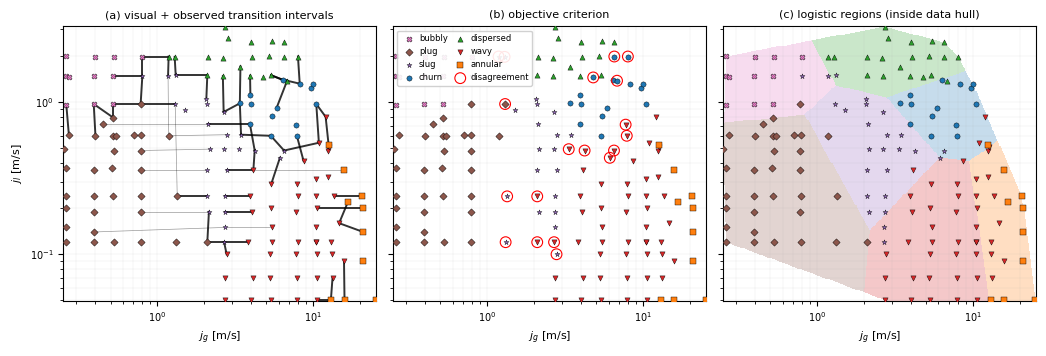

In [5]:
plt.rcParams.update({'font.size': 8, 'axes.labelsize': 8, 'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 6})
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.6), sharex=True, sharey=True)
order = [p for p in OBJECTIVE_PATTERNS]
colors = {p: styles[p]['color'] for p in order}

for ax in axes:
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel(r'$j_g$ [m/s]')
    ax.grid(alpha=0.3, which='both', linewidth=0.3)
axes[0].set_ylabel(r'$j_l$ [m/s]')

def scatter(ax, column, edge=None):
    for p in order:
        sub = df[df[column] == p]
        ax.scatter(sub['jg'], sub['jl'], s=14, marker=styles[p]['marker'], color=colors[p], edgecolor='k', linewidth=0.3, label=p, zorder=3)

scatter(axes[0], 'visual')
for _, r in transitions.iterrows():
    axes[0].plot([r['jg_low'], r['jg_high']], [r['jl_low'], r['jl_high']], color='k',
                 linewidth=1.4 if r['well_bracketed'] else 0.5, alpha=0.8 if r['well_bracketed'] else 0.4, zorder=2)
axes[0].set_title('(a) visual + observed transition intervals', fontsize=8)

scatter(axes[1], 'objective_pattern')
wrong = df[df['visual'] != df['objective_pattern']]
axes[1].scatter(wrong['jg'], wrong['jl'], s=60, facecolor='none', edgecolor='r', linewidth=0.8, zorder=4, label='disagreement')
axes[1].set_title('(b) objective criterion', fontsize=8)

cls = list(model.classes_)
idx = np.array([cls.index(c) for c in base_grid]).astype(float)
idx[~inside] = np.nan
from matplotlib.colors import ListedColormap
cmap = ListedColormap([colors[c] for c in cls])
axes[2].pcolormesh(10 ** gx, 10 ** gy, idx.reshape(gx.shape), cmap=cmap, alpha=0.25, shading='auto', vmin=-0.5, vmax=len(cls) - 0.5)
scatter(axes[2], 'visual')
axes[2].set_title('(c) logistic regions (inside data hull)', fontsize=8)

axes[1].legend(loc='upper left', frameon=True, framealpha=0.9, ncol=2, handletextpad=0.2, columnspacing=0.5)
fig.tight_layout()
fig.savefig(out / 'draft_flow_map.pdf')
fig.savefig(out / 'draft_flow_map.png', dpi=200)
plt.show()